# 📡 Análise de Churn de uma Empresa de Internet por Assinatura

Estudo de caso de análise de dados e modelagem com **Python** e **SQL**, seguindo a metodologia **CRISP-DM**.

## Índice

1. Entendimento do Negócio e Contextualização
2. Bibliotecas Utilizadas
3. Carregamento dos Dados
4. Descrição dos Dados
5. Limpeza e Preparação dos Dados
6. Análise Exploratória
7. Modelagem
8. Conclusões e Recomendações
9. Deploy: Como Reproduzir este Projeto

# 1- Entendimento do Negócio e Contextualização

## A história da NetVida Telecom

Em 2019, em Curitiba (PR), o Sérgio e a Patrícia, dois amigos que trabalhavam com redes de computadores, ficaram incomodados com a internet lenta e cara do bairro onde moravam. Em vez de reclamar, resolveram instalar a própria rede de fibra óptica.

Começaram atendendo os vizinhos da rua. Deu tão certo que nasceu a **NetVida Telecom**, um provedor de internet por assinatura que hoje atende vários estados. Os planos variam de acordo com a velocidade, e os clientes podem contratar também serviços extras, como suporte técnico premium e TV por streaming.

Com o crescimento, apareceu um problema que não dá para resolver com mais cabos: **todo mês, parte dos clientes cancela o serviço**. Esse cancelamento tem nome, **churn**.

O Sérgio e a Patrícia sabem que conquistar um cliente novo custa muito mais do que manter um que já existe. Mas até hoje a retenção era feita no "feeling": ligavam para quem reclamava mais alto e deixavam passar quem cancelava em silêncio.

Agora eles querem decisões baseadas em dados. Por isso contrataram uma pessoa para analisar a base de clientes e descobrir **quem cancela, por quê e quem está prestes a cancelar**.

Esse alguém é você, o(a) analista de dados. 🚀

## Problema de negócio

> **Como reduzir o cancelamento de clientes da NetVida e usar os dados para agir antes que eles saiam?**

## Perguntas que a análise vai responder

1. Qual é a **taxa de churn** da empresa?
2. O churn muda conforme o **tipo de contrato** e o **plano**?
3. Clientes **novos** cancelam mais que os clientes antigos?
4. **Chamados de suporte** e **atrasos de pagamento** têm relação com o cancelamento?
5. Quais clientes ativos têm **maior risco** de cancelar?

## Objetivo do projeto

Entender o perfil de quem cancela e construir um modelo simples que aponte os clientes com maior risco, para a diretoria montar uma campanha de retenção.

## Sobre os dados

Os dados deste projeto são **fictícios**. Eles foram gerados por um script (`generate_data.py`) para simular a rotina de uma empresa real, incluindo problemas comuns como valores nulos e registros duplicados. Qualquer semelhança com empresas reais é coincidência.

## Ferramentas

- **Python** (pandas, matplotlib, seaborn e scikit-learn)
- **SQL** (SQLite)
- **Jupyter Notebook**
- **Git** para versionamento

# 2- Bibliotecas Utilizadas

Aqui ficam as bibliotecas que o projeto usa. Deixar tudo importado no começo do notebook ajuda quem for reproduzir a análise a ver rapidinho o que precisa ter instalado.

| Biblioteca | Para que serve neste projeto |
|---|---|
| `pandas` | Carregar, limpar e analisar as tabelas |
| `sqlite3` | Rodar consultas SQL dentro do notebook (já vem com o Python) |
| `matplotlib` | Criar os gráficos |
| `seaborn` | Deixar os gráficos mais bonitos e fáceis de montar |
| `scikit-learn` | Construir o modelo que aponta os clientes com risco de cancelar |

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3- Carregamento dos Dados

A NetVida entregou os dados de 2025 em **três arquivos CSV**, que se relacionam entre si pelo código do cliente (`customer_id`):

| Arquivo | Conteúdo | Chave de ligação |
|---|---|---|
| `customers.csv` | Cadastro e contrato dos clientes | `customer_id` |
| `tickets.csv` | Chamados de suporte abertos | `ticket_id` e `customer_id` |
| `payments.csv` | Faturas mensais dos clientes | `invoice_id` e `customer_id` |

Vamos carregar cada arquivo em um DataFrame do pandas. As colunas de data já são lidas como data, para facilitar as análises por período.

In [2]:
customers = pd.read_csv('customers.csv', parse_dates=['signup_date', 'cancel_date'])
tickets = pd.read_csv('tickets.csv', parse_dates=['open_date'])
payments = pd.read_csv('payments.csv', parse_dates=['due_date','payment_date'])

print('customers:', customers.shape)
print('tickets:', tickets.shape)
print('payments:', payments.shape)

customers: (3020, 8)
tickets: (3597, 4)
payments: (30458, 5)


# 4- Descrição dos Dados

Antes de limpar ou analisar, precisamos **conhecer os dados**: como as tabelas são, quais colunas existem e de que tipo é cada uma.

## 4.1 Dicionário de dados

| Tabela | Coluna | Descrição |
|---|---|---|
| `customers` | `customer_id` | Código único do cliente |
| `customers` | `state` | Estado (UF) do cliente |
| `customers` | `signup_date` | Data de adesão ao serviço |
| `customers` | `plan` | Plano contratado (velocidade) |
| `customers` | `contract_type` | Tipo de contrato (Mensal, Anual ou Bienal) |
| `customers` | `payment_method` | Forma de pagamento |
| `customers` | `monthly_fee` | Mensalidade em reais |
| `customers` | `cancel_date` | Data de cancelamento (vazia se o cliente continua ativo) |
| `tickets` | `ticket_id` | Código único do chamado |
| `tickets` | `customer_id` | Cliente que abriu o chamado |
| `tickets` | `open_date` | Data de abertura do chamado |
| `tickets` | `reason` | Motivo do chamado |
| `payments` | `invoice_id` | Código único da fatura |
| `payments` | `customer_id` | Cliente dono da fatura |
| `payments` | `due_date` | Data de vencimento |
| `payments` | `payment_date` | Data do pagamento (vazia se a fatura não foi paga até o fim de 2025) |
| `payments` | `amount` | Valor da fatura em reais |

## 4.2 Primeiras linhas de cada tabela

In [3]:
display(customers.head())
display(tickets.head())
display(payments.head())

,customer_id,state,signup_date,plan,contract_type,payment_method,monthly_fee,cancel_date
0,1,SC,2021-10-08,Premium 600MB,Mensal,Pix,149.9,NaT
1,2,PR,2022-12-16,Intermediário 300MB,Bienal,Débito automático,109.9,NaT
2,3,PR,2022-07-05,Intermediário 300MB,Mensal,Boleto,109.9,NaT
3,4,NaN,2022-05-31,Básico 100MB,Mensal,Boleto,79.9,2025-10-23
4,5,RS,2023-11-25,Básico 100MB,Anual,Cartão de crédito,79.9,NaT


,ticket_id,customer_id,open_date,reason
0,1,2699,2025-01-01,Dúvidas
1,2,2143,2025-01-01,Dúvidas
2,3,1154,2025-01-01,Instalação
3,4,366,2025-01-01,Instalação
4,5,1854,2025-01-01,Queda de conexão


,invoice_id,customer_id,due_date,payment_date,amount
0,1,1,2025-01-10,2025-01-08,149.9
1,2,2,2025-01-10,2025-01-09,109.9
2,3,3,2025-01-10,2025-01-13,109.9
3,4,4,2025-01-10,2025-01-09,79.9
4,5,5,2025-01-10,2025-01-07,79.9


## 4.3 Tipos de dados de cada coluna

In [4]:
customers.info()
print('\n')
tickets.info()
print('\n')
payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 3020 entries, 0 to 3019
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customer_id     3020 non-null   int64         
 1   state           2929 non-null   str           
 2   signup_date     3020 non-null   datetime64[us]
 3   plan            3020 non-null   str           
 4   contract_type   3020 non-null   str           
 5   payment_method  3020 non-null   str           
 6   monthly_fee     2960 non-null   float64       
 7   cancel_date     717 non-null    datetime64[us]
dtypes: datetime64[us](2), float64(1), int64(1), str(4)
memory usage: 188.9 KB


<class 'pandas.DataFrame'>
RangeIndex: 3597 entries, 0 to 3596
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   ticket_id    3597 non-null   int64         
 1   customer_id  3597 non-null   int64         
 2   open_dat

## 4.4 Valores nulos

Primeiro, quantos valores vazios existem em cada coluna. Lembrando que nem todo vazio é problema: `cancel_date` vazia significa cliente ativo e `payment_date` vazia significa fatura não paga.

In [7]:
print(customers.isnull().sum())
print('\n')
print(tickets.isnull().sum())
print('\n')
print(payments.isnull().sum())

customer_id          0
state               91
signup_date          0
plan                 0
contract_type        0
payment_method       0
monthly_fee         60
cancel_date       2303
dtype: int64


ticket_id      0
customer_id    0
open_date      0
reason         0
dtype: int64


invoice_id        0
customer_id       0
due_date          0
payment_date    604
amount            0
dtype: int64


## 4.5 Linhas duplicadas

Agora, quantas linhas estão repetidas em cada tabela.

In [9]:
print('customers:', customers.duplicated().sum())
print('tickets:', tickets.duplicated().sum())
print('payments:', payments.duplicated().sum())

customers: 20
tickets: 30
payments: 50


## 4.6 Textos escritos de formas diferentes

Em colunas de categoria, cada valor deveria estar escrito de **um único jeito**. Vamos olhar os valores únicos de `payment_method` e `reason`.

In [11]:
print(customers['payment_method'].unique())
print('\n')
print(tickets['reason'].unique())

<StringArray>
[               'Pix',  'Débito automático',             'Boleto',
  'Cartão de crédito',  'CARTÃO DE CRÉDITO',            'Boleto ',
  'DÉBITO AUTOMÁTICO', 'Cartão de crédito ',             'BOLETO',
 'Débito automático ',                'PIX',               'Pix ']
Length: 12, dtype: str


<StringArray>
[         'Dúvidas',       'Instalação', 'Queda de conexão',
         'Lentidão',         'Cobrança',         'lentidão',
          'DÚVIDAS',         'COBRANÇA', 'queda de conexão',
       'INSTALAÇÃO', 'QUEDA DE CONEXÃO',         'LENTIDÃO',
         'cobrança',          'dúvidas']
Length: 14, dtype: str


## 4.7 Datas que não fazem sentido

Um cliente não pode cancelar antes de ter contratado o serviço. Vamos conferir se existe algum caso assim.

In [12]:
print('cancel before signup:', (customers['cancel_date'] < customers['signup_date']).sum())
print('first cancel date:', customers['cancel_date'].min())

cancel before signup: 10
first cancel date: 2019-06-11 00:00:00


## 4.8 Resumo dos problemas encontrados

| Tabela | Problema | O que fazer na limpeza |
|---|---|---|
| `customers` | Estados vazios | Preencher com `'Não informado'` |
| `customers` | Mensalidades vazias | Preencher com o valor do plano do cliente |
| `customers` | Formas de pagamento escritas de jeitos diferentes | Padronizar a escrita |
| `customers` | Cancelamento antes da adesão | Manter o cliente como churn e descartar a data errada |
| `customers` | Linhas duplicadas | Remover as repetições |
| `tickets` | Motivos escritos de jeitos diferentes | Padronizar a escrita |
| `tickets` | Linhas duplicadas | Remover as repetições |
| `payments` | Linhas duplicadas | Remover as repetições |
| `payments` | Data de pagamento vazia | Manter: significa fatura não paga |

Com esse mapa em mãos, a limpeza na próxima seção fica direta ao ponto: cada problema encontrado aqui tem uma solução prevista.

# 5- Limpeza e Preparação dos Dados

Nesta etapa, cada problema encontrado na seção 4 recebe uma correção. Depois de cada uma, conferimos o resultado para ter certeza de que deu certo.

## 5.1 Limpeza da tabela `customers`

Correções desta tabela:
- Remover as linhas duplicadas
- Preencher os estados vazios com `'Não informado'`
- Preencher as mensalidades vazias com o valor do plano do cliente, já que cada plano tem um preço único
- Padronizar a escrita da forma de pagamento
- Criar a coluna `churn`, com 1 para quem cancelou e 0 para quem continua ativo
- Descartar as datas de cancelamento anteriores à adesão. Sabemos que esses clientes cancelaram, mas a data correta é impossível de recuperar, então eles continuam como churn e a coluna `churn` é a referência para saber quem cancelou

In [15]:
customers = customers.drop_duplicates().reset_index(drop=True)

customers['state'] = customers['state'].fillna('Não informado')
customers['monthly_fee'] = customers['monthly_fee'].fillna(customers.groupby('plan')['monthly_fee'].transform('max'))
customers['payment_method'] = customers['payment_method'].str.strip().str.capitalize()

customers['churn'] = customers['cancel_date'].notna().astype(int)
wrong_date = customers['cancel_date'] < customers['signup_date']
customers.loc[wrong_date, 'cancel_date'] = pd.NaT

In [17]:
print(customers.shape)
print('\n')
print(customers.duplicated().sum())
print('\n')
print(customers[['state', 'monthly_fee']].isnull().sum())
print('\n')
print(customers['payment_method'].unique())
print('\n')
print(customers['churn'].value_counts())
print('\n')
print((customers['cancel_date'] < customers['signup_date']).sum())

(3000, 9)


0


state          0
monthly_fee    0
dtype: int64


<StringArray>
['Pix', 'Débito automático', 'Boleto', 'Cartão de crédito']
Length: 4, dtype: str


churn
0    2288
1     712
Name: count, dtype: int64


0


## 5.2 Limpeza da tabela `tickets`

Correções desta tabela:
- Remover as linhas duplicadas
- Padronizar a escrita dos motivos (`'LENTIDÃO'` e `'lentidão'` viram `'Lentidão'`)

In [18]:
tickets = tickets.drop_duplicates().reset_index(drop=True)
tickets['reason'] = tickets['reason'].str.strip().str.capitalize()

In [19]:
print(tickets.shape)
print(tickets.duplicated().sum())
print(tickets['reason'].value_counts())

(3567, 4)
0
reason
Lentidão            897
Queda de conexão    846
Dúvidas             756
Cobrança            728
Instalação          340
Name: count, dtype: int64


## 5.3 Limpeza da tabela `payments`

Correção desta tabela:
- Remover as linhas duplicadas

As datas de pagamento vazias **não são um problema**: significam fatura não paga até o fim de 2025. Elas ficam como estão e serão tratadas como atraso na análise.

In [20]:
payments = payments.drop_duplicates().reset_index(drop=True)

In [21]:
print(payments.shape)
print(payments.duplicated().sum())
print(payments['payment_date'].isnull().sum())

(30408, 5)
0
603


## 5.4 Criação do banco de dados SQLite

Com os dados limpos, vamos criar um banco **SQLite** com as três tabelas. Assim, as perguntas de negócio podem ser respondidas com **SQL** e com **Python**, como acontece no dia a dia de um analista.

O banco é criado **na memória**: ele existe enquanto o notebook está aberto e é montado de novo a cada execução. Por isso não gera nenhum arquivo extra e o projeto continua simples de reproduzir.

In [25]:
conn = sqlite3.connect(':memory:')

customers.to_sql('customers', conn, index=False)
tickets.to_sql('tickets', conn, index=False)
payments.to_sql('payments', conn, index=False)

30408

In [26]:
query = '''
SELECT name
FROM sqlite_master
WHERE type = 'table'
'''
display(pd.read_sql(query, conn))

query = '''
SELECT (SELECT COUNT(*) FROM customers) AS total_customers,
       (SELECT COUNT(*) FROM tickets) AS total_tickets,
       (SELECT COUNT(*) FROM payments) AS total_payments
'''
display(pd.read_sql(query, conn))

,name
0,customers
1,tickets
2,payments


,total_customers,total_tickets,total_payments
0,3000,3567,30408


# 6- Análise Exploratória

Nesta etapa, cada pergunta de negócio da seção 1 é respondida com **SQL** e visualizada com **Python**.

## Como o churn é medido

- **Churn:** cliente que cancelou o serviço entre 01/01/2025 e 31/12/2025. Na base, ele é identificado pela coluna `churn` (1 para quem cancelou e 0 para quem continua ativo).
- **Taxa de churn:** percentual de clientes que cancelaram, em relação ao total de clientes da base.

## 6.1 Qual é a taxa de churn da empresa?

In [27]:
query = '''
SELECT CASE WHEN churn = 1 THEN 'Cancelou' ELSE 'Ativo' END AS customer_status,
       COUNT(*) AS total_customers,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM customers), 1) AS percentage
FROM customers
GROUP BY churn
ORDER BY churn DESC
'''

churn_rate = pd.read_sql(query, conn)
display(churn_rate)

,customer_status,total_customers,percentage
0,Cancelou,712,23.7
1,Ativo,2288,76.3


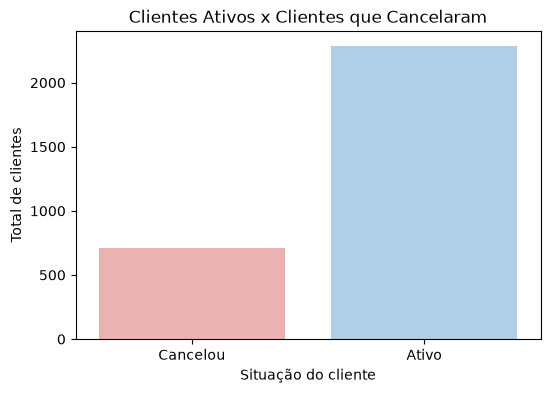

In [32]:
plt.figure(figsize=(6, 4))
sns.barplot(data=churn_rate, x='customer_status', y='total_customers', hue='customer_status',
            palette={'Ativo': '#a8d0f0', 'Cancelou': '#f4a9a8'}, legend=False)
plt.title('Clientes Ativos x Clientes que Cancelaram')
plt.xlabel('Situação do cliente')
plt.ylabel('Total de clientes')
plt.show()

### Observações

- Dos **3000 clientes** da base, **712 (23,7%)** cancelaram o serviço em 2025. Isso significa que cerca de 1 em cada 4 clientes saiu da NetVida no ano.
- A grande maioria (76,3%) continua ativa, mas uma perda desse tamanho em um único ano é relevante para uma empresa de assinatura.
- Este número é uma média geral. Ele não mostra **quais clientes** cancelam mais, e é isso que as próximas perguntas investigam.

### Recomendação

Tratar o churn como prioridade da diretoria e olhar os grupos de clientes que mais cancelam, para direcionar a campanha de retenção onde ela terá mais efeito.

## 6.2 O churn muda conforme o tipo de contrato e o plano?

Aqui vamos calcular a taxa de churn de cada grupo de clientes: de todos os clientes do grupo, qual percentual cancelou. Assim dá para comparar os grupos de forma justa, mesmo que eles tenham tamanhos diferentes.

### Churn por tipo de contrato

In [37]:
query = '''
SELECT contract_type,
       COUNT(*) AS total_customers,
       SUM(churn) AS canceled_customers,
       ROUND(SUM(churn) * 100.0 / COUNT(*), 1) AS churn_rate
FROM customers
GROUP BY contract_type
ORDER BY churn_rate DESC
'''

churn_by_contract = pd.read_sql(query, conn)
display(churn_by_contract)

,contract_type,total_customers,canceled_customers,churn_rate
0,Mensal,1494,513,34.3
1,Anual,910,135,14.8
2,Bienal,596,64,10.7


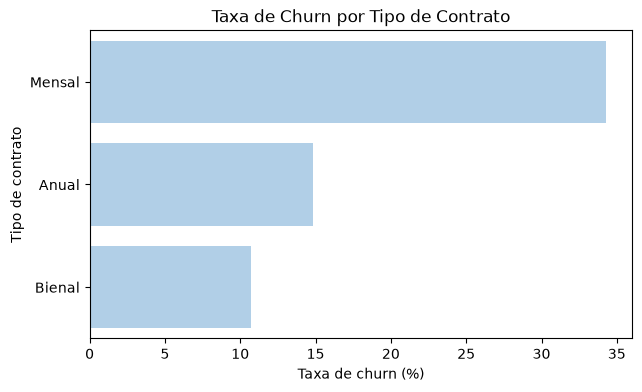

In [38]:
plt.figure(figsize=(7, 4))
sns.barplot(data=churn_by_contract, x='churn_rate', y='contract_type', color='#a8d0f0')
plt.title('Taxa de Churn por Tipo de Contrato')
plt.xlabel('Taxa de churn (%)')
plt.ylabel('Tipo de contrato')
plt.show()

### Churn por plano

In [39]:
query = '''
SELECT plan,
       COUNT(*) AS total_customers,
       SUM(churn) AS canceled_customers,
       ROUND(SUM(churn) * 100.0 / COUNT(*), 1) AS churn_rate
FROM customers
GROUP BY plan
ORDER BY churn_rate DESC
'''

churn_by_plan = pd.read_sql(query, conn)
display(churn_by_plan)

,plan,total_customers,canceled_customers,churn_rate
0,Básico 100MB,1336,350,26.2
1,Intermediário 300MB,1101,240,21.8
2,Premium 600MB,563,122,21.7


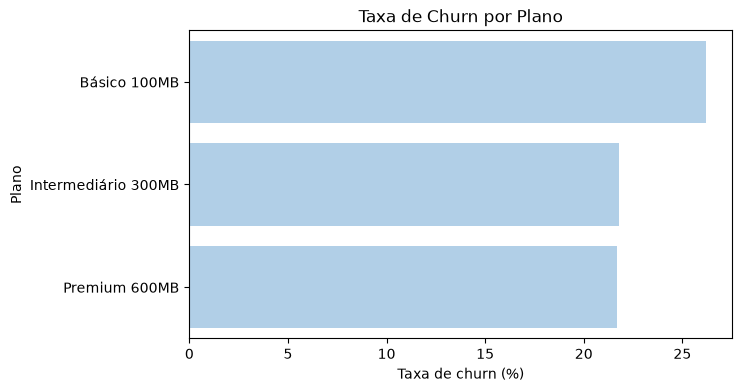

In [40]:
plt.figure(figsize=(7, 4))
sns.barplot(data=churn_by_plan, x='churn_rate', y='plan', color='#a8d0f0')
plt.title('Taxa de Churn por Plano')
plt.xlabel('Taxa de churn (%)')
plt.ylabel('Plano')
plt.show()

### Observações

- O **contrato Mensal** tem a maior taxa de churn, **34,3%**, bem acima da média geral de 23,7%. O contrato **Anual** tem 14,8% e o **Bienal** tem 10,7%.
- A taxa do contrato Mensal é mais que o dobro da do Anual e cerca de três vezes a do Bienal.
- O contrato Mensal concentra **513 dos 712 cancelamentos**, ou seja, cerca de 72% de todos os clientes que saíram.
- Quanto ao **plano**, o **Básico** tem a maior taxa, **26,2%**, enquanto o **Intermediário (21,8%)** e o **Premium (21,7%)** ficam praticamente iguais e abaixo da média geral.
- A diferença entre os planos é bem menor do que a diferença entre os contratos. Isso indica que o **tipo de contrato pesa mais** no cancelamento do que a velocidade contratada.
- Uma possível explicação para o contrato Mensal é a ausência de fidelidade, o que facilita a saída. Para o plano Básico, pode ser sensibilidade a preço. São hipóteses, porque a base não traz informações sobre multa contratual ou promoções.

### Recomendação

Priorizar a **migração de clientes do contrato Mensal para o Anual**, com um benefício como desconto na mensalidade ou instalação de um serviço extra. É o grupo que mais cancela e onde a ação de retenção tem mais efeito. O plano Básico merece atenção, mas como segunda prioridade.

## 6.3 Clientes novos cancelam mais que os antigos?

Aqui vamos calcular a taxa de churn de acordo com o ano em que o cliente aderiu ao serviço. Quanto mais recente o ano, menos tempo de casa o cliente tem.

In [41]:
query = '''
SELECT strftime('%Y', signup_date) AS signup_year,
       COUNT(*) AS total_customers,
       SUM(churn) AS canceled_customers,
       ROUND(SUM(churn) * 100.0 / COUNT(*), 1) AS churn_rate
FROM customers
GROUP BY signup_year
ORDER BY signup_year
'''

churn_by_year = pd.read_sql(query, conn)
display(churn_by_year)

,signup_year,total_customers,canceled_customers,churn_rate
0,2019,269,50,18.6
1,2020,433,90,20.8
2,2021,487,109,22.4
3,2022,488,94,19.3
4,2023,465,90,19.4
5,2024,506,174,34.4
6,2025,352,105,29.8


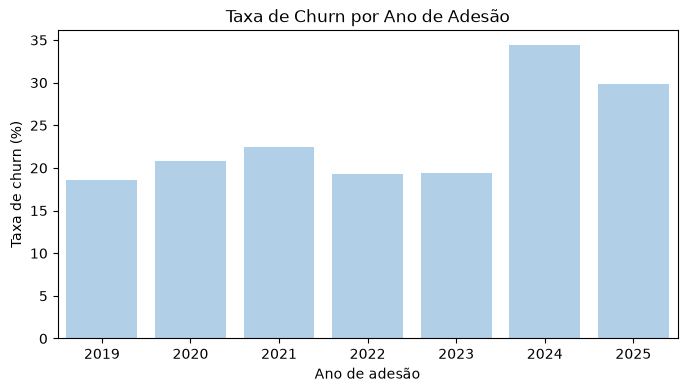

In [42]:
plt.figure(figsize=(8, 4))
sns.barplot(data=churn_by_year, x='signup_year', y='churn_rate', color='#a8d0f0')
plt.title('Taxa de Churn por Ano de Adesão')
plt.xlabel('Ano de adesão')
plt.ylabel('Taxa de churn (%)')
plt.show()